Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')

#For ignoring warning
import warnings
warnings.filterwarnings("ignore")

Importing dataset

In [2]:
data = pd.read_csv('Zim_Airline.csv')

In [3]:
data.head()

,satisfaction,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Female,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,...,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Male,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,...,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Female,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,...,2,2,3,3,4,4,4,2,0,0.0
3,satisfied,Female,Loyal Customer,60,Personal Travel,Eco,623,0,0,0,...,3,1,1,0,1,4,1,3,0,0.0
4,satisfied,Female,Loyal Customer,70,Personal Travel,Eco,354,0,0,0,...,4,2,2,0,2,4,2,5,0,0.0


## EXPLORATORY DATA ANALYSIS

Customer satisfaction

In [4]:
data['satisfaction'].value_counts()

satisfied       71087
dissatisfied    58793
Name: satisfaction, dtype: int64

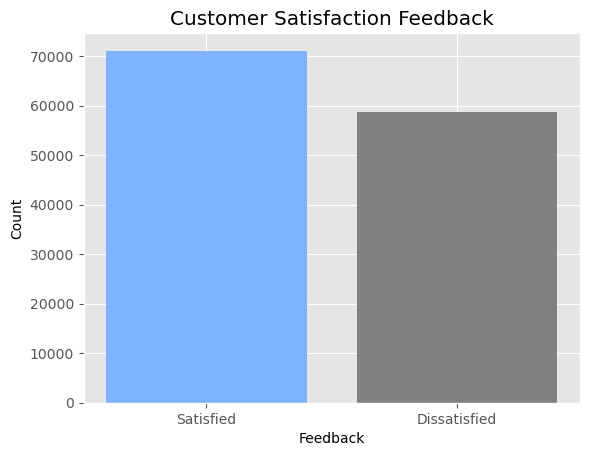

In [5]:
# Data
labels = ['Satisfied', 'Dissatisfied']
values = [71087, 58793]

# Light blue and green colors (RGB values)
light_blue = (0.5, 0.7, 1.0)  # Light blue color
light_green = (0.5, 0.5, 0.5)  # Light green color

# Plotting
plt.bar(labels, values, color=[light_blue, light_green])
plt.xlabel('Feedback')
plt.ylabel('Count')
plt.title('Customer Satisfaction Feedback')
plt.show()

Gender distribution

In [6]:
data['Gender'].value_counts()

Female    65899
Male      63981
Name: Gender, dtype: int64

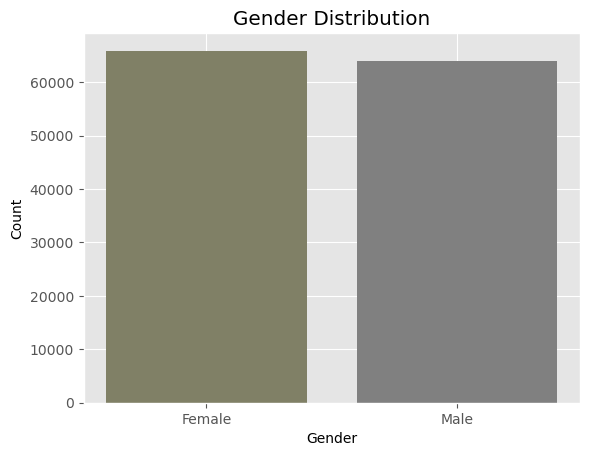

In [7]:
# Count occurrences of each unique value
value_counts = data['Gender'].value_counts()
unique_values = ['Female', 'Male']

light_blue = (0.5, 0.5, 0.4)  
light_green = (0.5, 0.5, 0.5)  

# Plotting
plt.bar(unique_values, value_counts, color= [light_blue, light_green])  # You can customize the colors as needed
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Gender Distribution')
plt.show()

Customer satisfaction according to gender

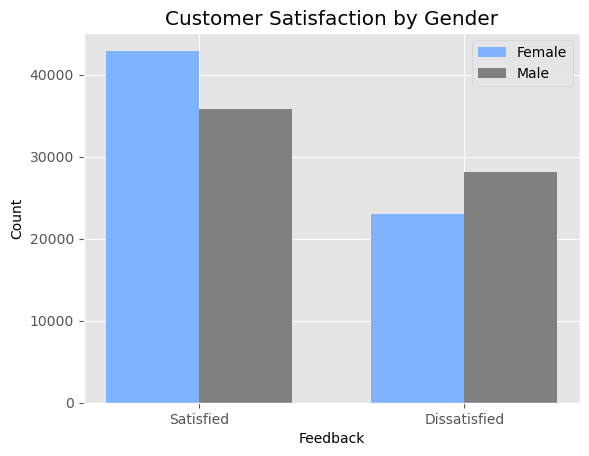

In [8]:
# Count occurrences of each unique value for gender
gender_counts = data['Gender'].value_counts()
unique_genders = ['Female', 'Male']

# Count occurrences of satisfaction by gender
satisfaction_counts_female = data[data['Gender'] == 'Female']['satisfaction'].value_counts()
satisfaction_counts_male = data[data['Gender'] == 'Male']['satisfaction'].value_counts()

# Light blue and green colors for satisfaction bars
light_blue = (0.5, 0.7, 1.0)  
light_green = (0.5, 0.5, 0.5) 

# Plotting
labels = ['Satisfied', 'Dissatisfied']
x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()

# Plot satisfaction by gender
ax.bar(x - width/2, satisfaction_counts_female, width, label='Female', color=light_blue)
ax.bar(x + width/2, satisfaction_counts_male, width, label='Male', color=light_green)

# Add some text for labels, title, and legend
ax.set_xlabel('Feedback')
ax.set_ylabel('Count')
ax.set_title('Customer Satisfaction by Gender')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.show()

Age distribution

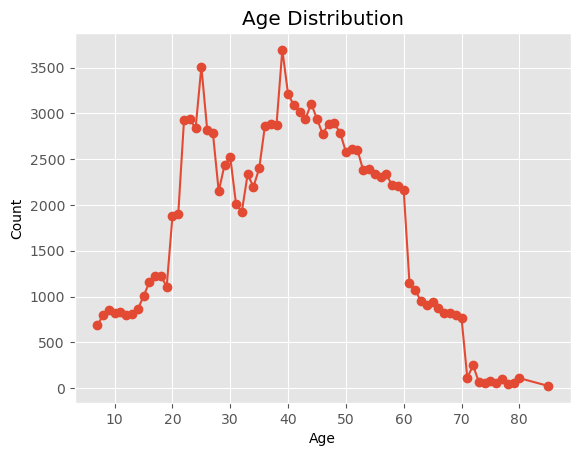

In [9]:
# Filter unique ages from the DataFrame
unique_ages = data['Age'].unique()
unique_ages.sort()

# Calculate counts for each unique age
counts = [data[data['Age'] == age]['Age'].count() for age in unique_ages]

# Plotting
plt.plot(unique_ages, counts, marker='o', linestyle='-')
plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age Distribution')
plt.grid(True)  # Add grid lines
plt.show()

Age distribution of satisfied and dissatisfied customers

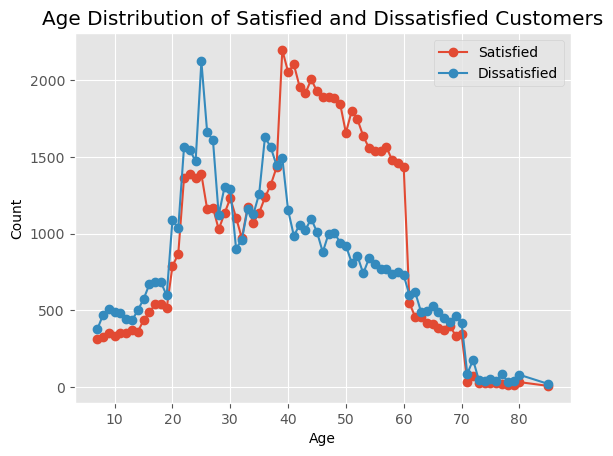

In [10]:
# Filter data for satisfied and dissatisfied customers
satisfied_data = data[data['satisfaction'] == 'satisfied']
dissatisfied_data = data[data['satisfaction'] == 'dissatisfied']

# Calculate counts for each unique age for satisfied and dissatisfied customers
unique_ages_satisfied = sorted(satisfied_data['Age'].unique())
unique_ages_dissatisfied = sorted(dissatisfied_data['Age'].unique())
counts_satisfied = [satisfied_data[satisfied_data['Age'] == age]['Age'].count() for age in unique_ages_satisfied]
counts_dissatisfied = [dissatisfied_data[dissatisfied_data['Age'] == age]['Age'].count() for age in unique_ages_dissatisfied]

# Plotting
plt.plot(unique_ages_satisfied, counts_satisfied, marker='o', linestyle='-', label='Satisfied')
plt.plot(unique_ages_dissatisfied, counts_dissatisfied, marker='o', linestyle='-', label='Dissatisfied')
plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age Distribution of Satisfied and Dissatisfied Customers')
plt.legend()
plt.grid(True)  # Add grid lines
plt.show()

Age distribution of different flight classes

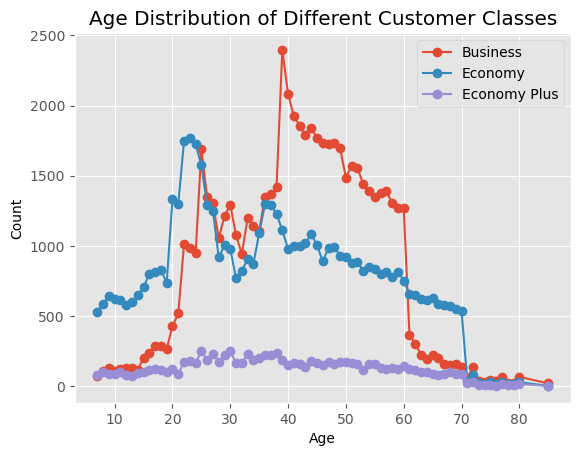

In [11]:
# Filter data for each class
business_data = data[data['Class'] == 'Business']
economy_data = data[data['Class'] == 'Eco']
economy_plus_data = data[data['Class'] == 'Eco Plus']

# Calculate counts for each unique age for each class
unique_ages_business = sorted(business_data['Age'].unique())
unique_ages_economy = sorted(economy_data['Age'].unique())
unique_ages_economy_plus = sorted(economy_plus_data['Age'].unique())
counts_business = [business_data[business_data['Age'] == age]['Age'].count() for age in unique_ages_business]
counts_economy = [economy_data[economy_data['Age'] == age]['Age'].count() for age in unique_ages_economy]
counts_economy_plus = [economy_plus_data[economy_plus_data['Age'] == age]['Age'].count() for age in unique_ages_economy_plus]

# Plotting
plt.plot(unique_ages_business, counts_business, marker='o', linestyle='-', label='Business')
plt.plot(unique_ages_economy, counts_economy, marker='o', linestyle='-', label='Economy')
plt.plot(unique_ages_economy_plus, counts_economy_plus, marker='o', linestyle='-', label='Economy Plus')
plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age Distribution of Different Customer Classes')
plt.legend()
plt.grid(True)  # Add grid lines
plt.show()

Summary statistics for continuous features

In [12]:
#Summary Statistics for continous features
continous_feat = data.columns[data.nunique()  > 4]
data[continous_feat].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,129880.0,39.427957,15.119360,7.0,27.0,40.0,51.0,85.0
Flight Distance,129880.0,1981.409055,1027.115606,50.0,1359.0,1925.0,2544.0,6951.0
Seat comfort,129880.0,2.838597,1.392983,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,2.990645,1.527224,0.0,2.0,3.0,4.0,5.0
Food and drink,129880.0,2.851994,1.443729,0.0,2.0,3.0,4.0,5.0
Gate location,129880.0,2.990422,1.305970,0.0,2.0,3.0,4.0,5.0
Inflight wifi service,129880.0,3.249130,1.318818,0.0,2.0,3.0,4.0,5.0
Inflight entertainment,129880.0,3.383477,1.346059,0.0,2.0,4.0,4.0,5.0
Online support,129880.0,3.519703,1.306511,0.0,3.0,4.0,5.0,5.0
Ease of Online booking,129880.0,3.472105,1.305560,0.0,2.0,4.0,5.0,5.0


Summary statistics for categorical features

In [13]:
#Summary Statistics for Binary categorical features
cat_col = data.columns[(data.nunique()  < 5)]
data[cat_col].describe().T

,count,unique,top,freq
satisfaction,129880,2,satisfied,71087
Gender,129880,2,Female,65899
Customer Type,129880,2,Loyal Customer,106100
Type of Travel,129880,2,Business travel,89693
Class,129880,3,Business,62160


Graphs of satisfaction 

In [14]:
# function for plotting
def plot(col, df=data):
    return df.groupby(col)['satisfaction'].value_counts(normalize=True).unstack().plot(kind='bar', figsize=(8,5))

Satisfaction according to gender

<Axes: xlabel='Gender'>

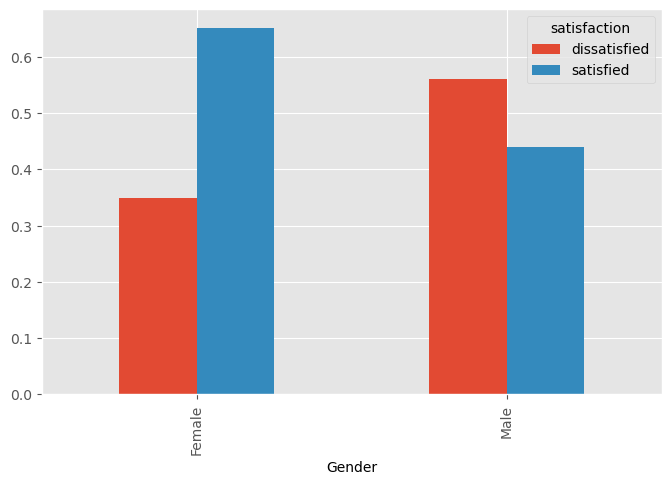

In [15]:
plot('Gender')

Satisfaction according to Customer Type

<Axes: xlabel='Customer Type'>

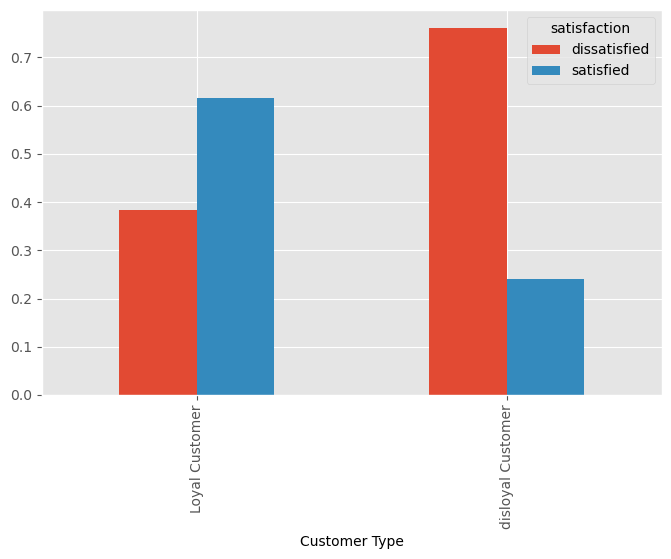

In [16]:
plot('Customer Type')

Satisfaction according to Flight class

<Axes: xlabel='Class'>

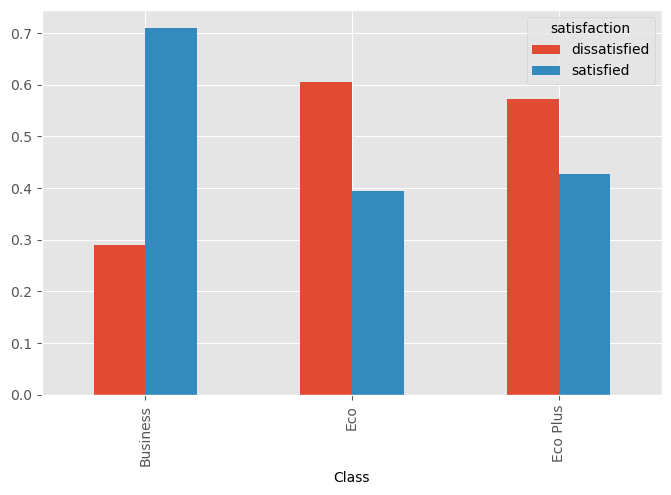

In [17]:
plot('Class')

Satisfaction according to Type of Travel

<Axes: xlabel='Type of Travel'>

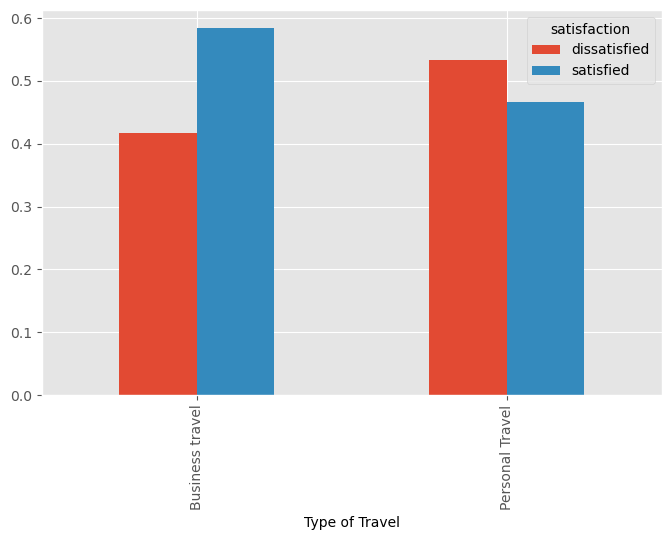

In [18]:

plot('Type of Travel')

Satisfaction and flight distance

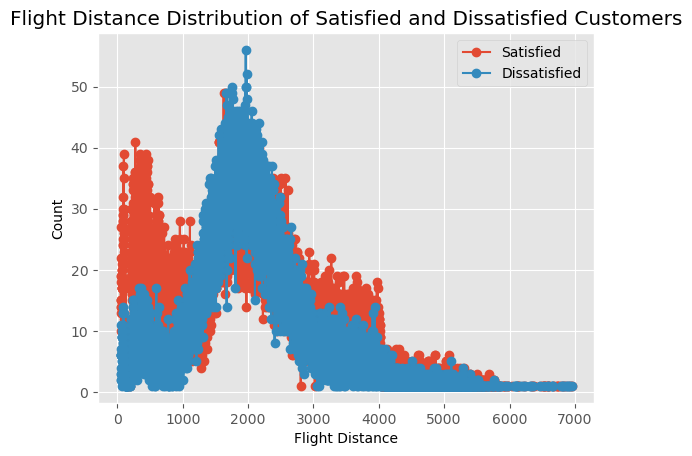

In [19]:
# Filter data for satisfied and dissatisfied customers
satisfied_data = data[data['satisfaction'] == 'satisfied']
dissatisfied_data = data[data['satisfaction'] == 'dissatisfied']

# Calculate counts for each unique flight distance for satisfied and dissatisfied customers
unique_distances_satisfied = sorted(satisfied_data['Flight Distance'].unique())
unique_distances_dissatisfied = sorted(dissatisfied_data['Flight Distance'].unique())
counts_satisfied = [satisfied_data[satisfied_data['Flight Distance'] == distance]['Flight Distance'].count() for distance in unique_distances_satisfied]
counts_dissatisfied = [dissatisfied_data[dissatisfied_data['Flight Distance'] == distance]['Flight Distance'].count() for distance in unique_distances_dissatisfied]

# Plotting
plt.plot(unique_distances_satisfied, counts_satisfied, marker='o', linestyle='-', label='Satisfied')
plt.plot(unique_distances_dissatisfied, counts_dissatisfied, marker='o', linestyle='-', label='Dissatisfied')
plt.xlabel('Flight Distance')
plt.ylabel('Count')
plt.title('Flight Distance Distribution of Satisfied and Dissatisfied Customers')
plt.legend()
plt.grid(True)  # Add grid lines
plt.show()

Delay times 

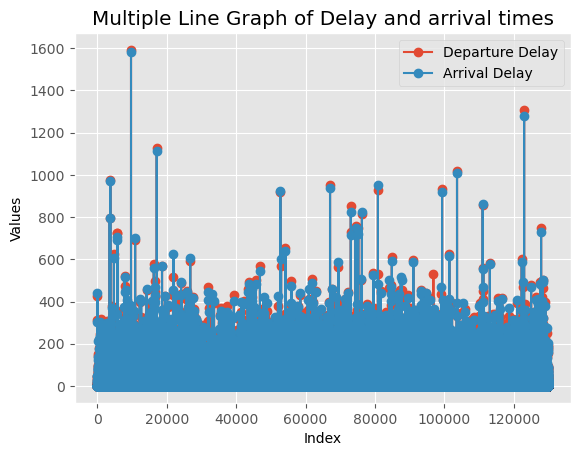

In [20]:
# Sample data (replace this with your own dataset)
feature1 = data['Departure Delay in Minutes']
feature2 = data['Arrival Delay in Minutes']

# Plotting
plt.plot(feature1, label='Departure Delay', marker='o')
plt.plot(feature2, label='Arrival Delay', marker='o')

# Add labels and title
plt.xlabel('Index')
plt.ylabel('Values')
plt.title('Multiple Line Graph of Delay and arrival times')
plt.legend()  

plt.grid(True)  
plt.show()

Departure Delay time and Satisfaction

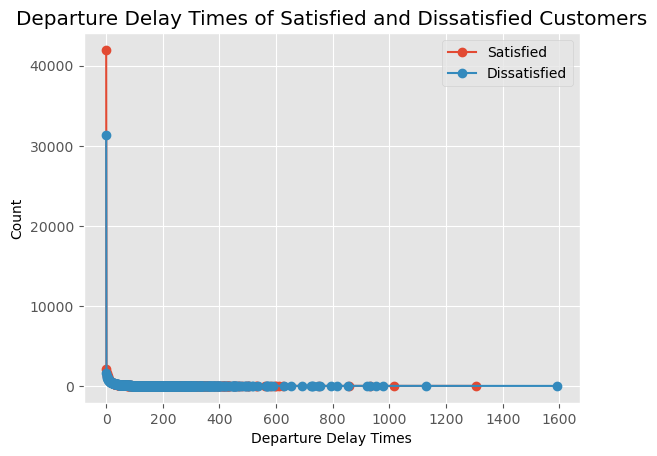

In [21]:
# Filter data for satisfied and dissatisfied customers
satisfied_data = data[data['satisfaction'] == 'satisfied']
dissatisfied_data = data[data['satisfaction'] == 'dissatisfied']

# Calculate counts for each unique flight distance for satisfied and dissatisfied customers
unique_distances_satisfied = sorted(satisfied_data['Departure Delay in Minutes'].unique())
unique_distances_dissatisfied = sorted(dissatisfied_data['Departure Delay in Minutes'].unique())
counts_satisfied = [satisfied_data[satisfied_data['Departure Delay in Minutes'] == distance]['Departure Delay in Minutes'].count() for distance in unique_distances_satisfied]
counts_dissatisfied = [dissatisfied_data[dissatisfied_data['Departure Delay in Minutes'] == distance]['Departure Delay in Minutes'].count() for distance in unique_distances_dissatisfied]

# Plotting
plt.plot(unique_distances_satisfied, counts_satisfied, marker='o', linestyle='-', label='Satisfied')
plt.plot(unique_distances_dissatisfied, counts_dissatisfied, marker='o', linestyle='-', label='Dissatisfied')
plt.xlabel('Departure Delay Times')
plt.ylabel('Count')
plt.title('Departure Delay Times of Satisfied and Dissatisfied Customers')
plt.legend()
plt.grid(True)  # Add grid lines
plt.show()

Arrival Delay times and satisfaction

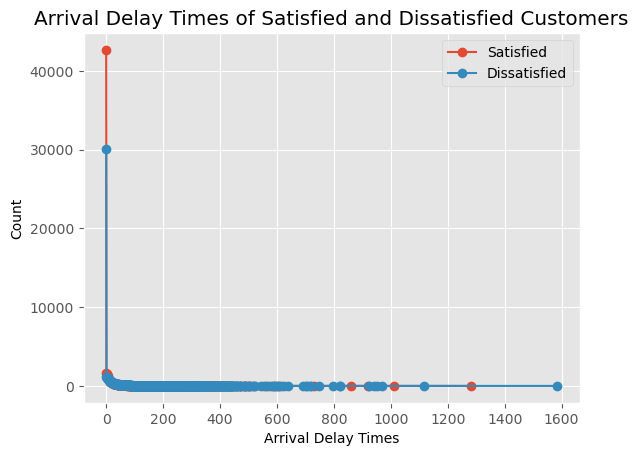

In [22]:
# Filter data for satisfied and dissatisfied customers
satisfied_data = data[data['satisfaction'] == 'satisfied']
dissatisfied_data = data[data['satisfaction'] == 'dissatisfied']

# Calculate counts for each unique flight distance for satisfied and dissatisfied customers
unique_distances_satisfied = sorted(satisfied_data['Arrival Delay in Minutes'].unique())
unique_distances_dissatisfied = sorted(dissatisfied_data['Arrival Delay in Minutes'].unique())
counts_satisfied = [satisfied_data[satisfied_data['Arrival Delay in Minutes'] == distance]['Arrival Delay in Minutes'].count() for distance in unique_distances_satisfied]
counts_dissatisfied = [dissatisfied_data[dissatisfied_data['Arrival Delay in Minutes'] == distance]['Arrival Delay in Minutes'].count() for distance in unique_distances_dissatisfied]

# Plotting
plt.plot(unique_distances_satisfied, counts_satisfied, marker='o', linestyle='-', label='Satisfied')
plt.plot(unique_distances_dissatisfied, counts_dissatisfied, marker='o', linestyle='-', label='Dissatisfied')
plt.xlabel('Arrival Delay Times')
plt.ylabel('Count')
plt.title('Arrival Delay Times of Satisfied and Dissatisfied Customers')
plt.legend()
plt.grid(True)  # Add grid lines
plt.show()

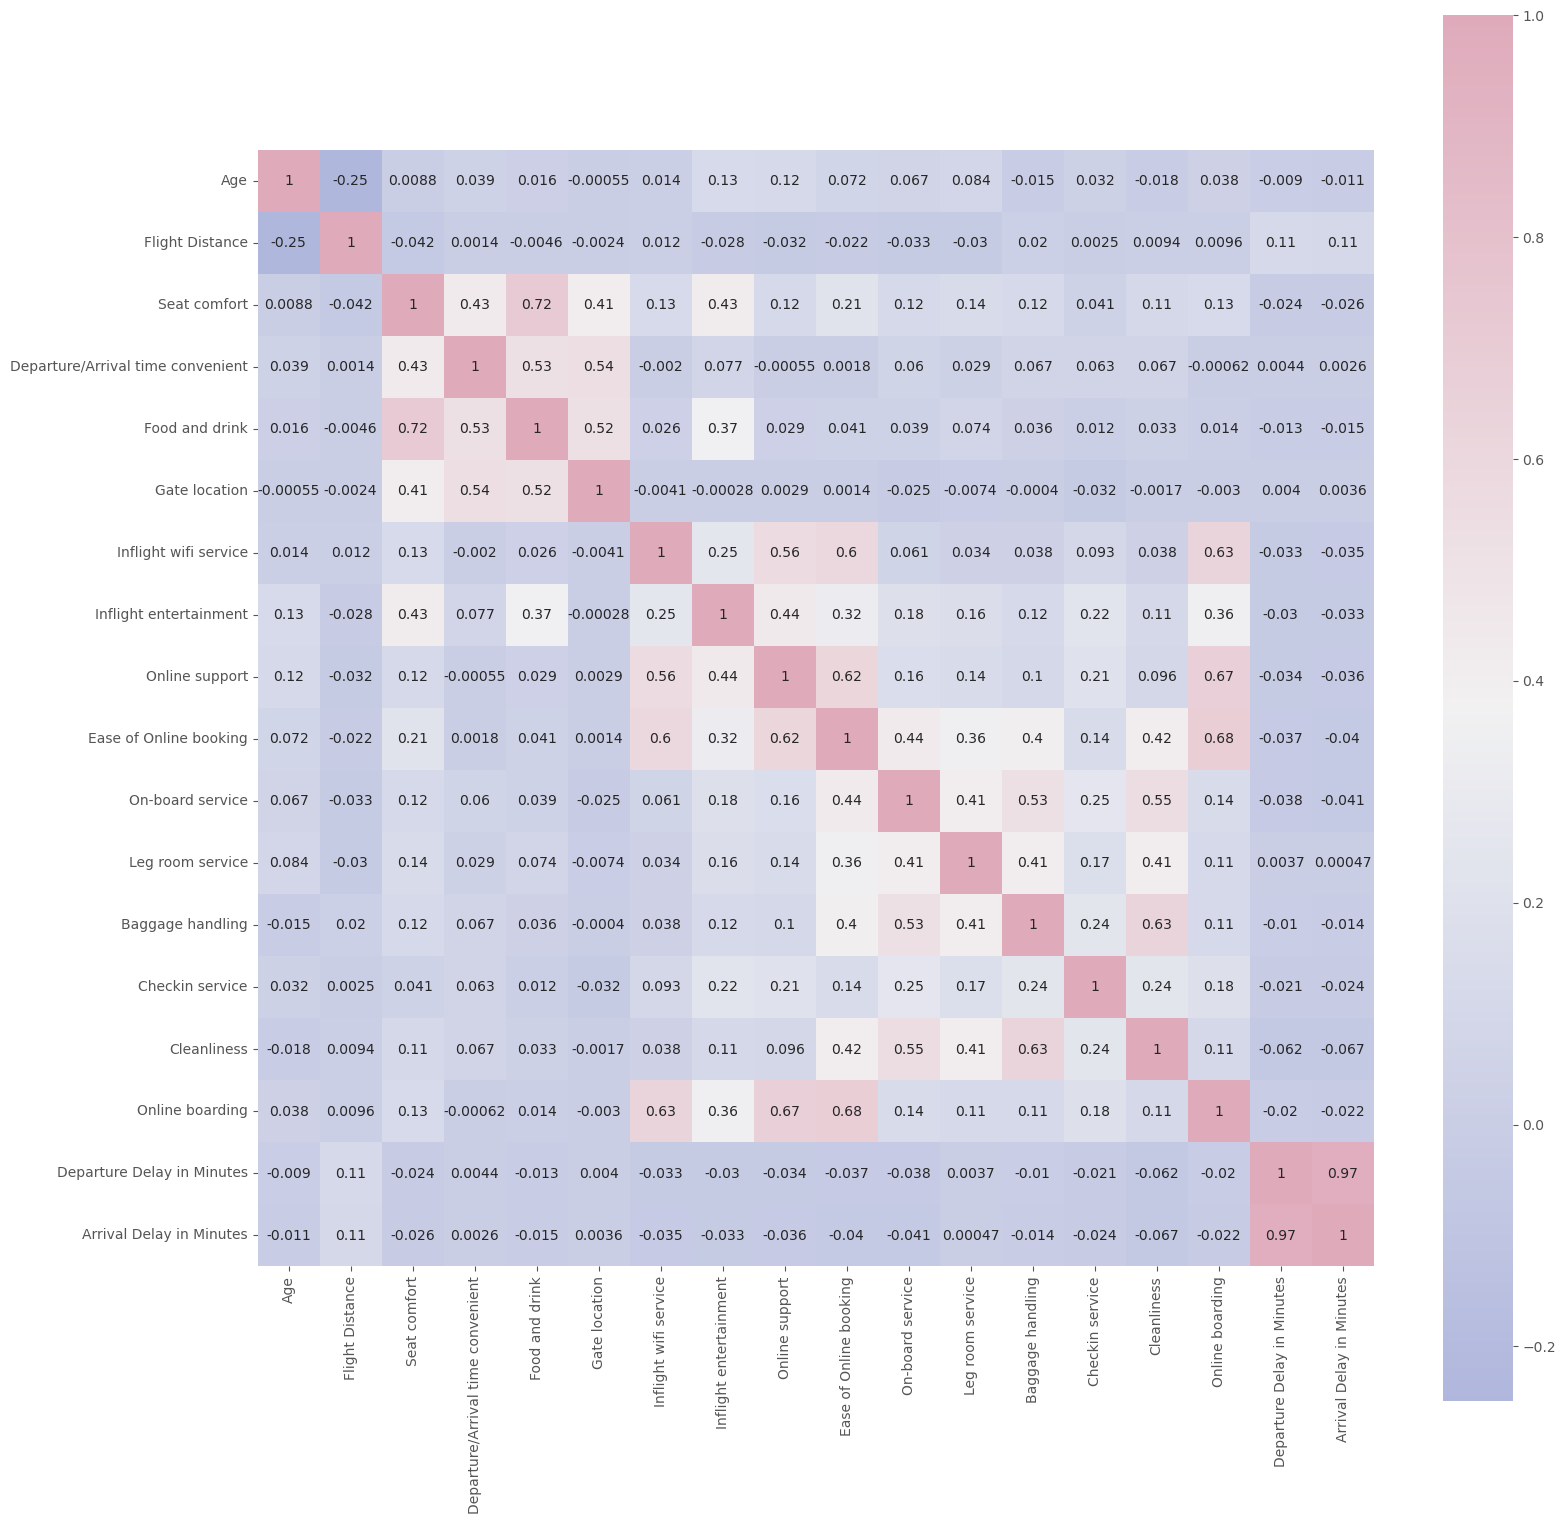

In [23]:
#Finding Correlation
cn=data.corr()
#Correlation 
cmap=sns.diverging_palette(260,-10,s=50, l=75, n=6,
as_cmap=True)
plt.subplots(figsize=(18,18))
sns.heatmap(cn,cmap=cmap,annot=True, square=True)
plt.show()

## Data preprocessing

Encoding categorical variables

In [24]:
#purpose
data['satisfaction'].replace(['dissatisfied',  'satisfied'],
                        [0,1], inplace=True)
data['Gender'].replace(['Female',  'Male'],
                        [0,1], inplace=True)
data['Customer Type'].replace(['disloyal Customer',  'Loyal Customer'],
                        [0,1], inplace=True)
data['Type of Travel'].replace(['Personal Travel','Business travel'],
                        [1,2], inplace=True)
data['Class'].replace(['Eco',  'Business','Eco Plus'],
                        [1,2,3], inplace=True)
data

,satisfaction,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,1,0,1,65,1,1,265,0,0,0,...,2,3,3,0,3,5,3,2,0,0.0
1,1,1,1,47,1,2,2464,0,0,0,...,2,3,4,4,4,2,3,2,310,305.0
2,1,0,1,15,1,1,2138,0,0,0,...,2,2,3,3,4,4,4,2,0,0.0
3,1,0,1,60,1,1,623,0,0,0,...,3,1,1,0,1,4,1,3,0,0.0
4,1,0,1,70,1,1,354,0,0,0,...,4,2,2,0,2,4,2,5,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,1,0,0,29,1,1,1731,5,5,5,...,2,2,3,3,4,4,4,2,0,0.0
129876,0,1,0,63,1,2,2087,2,3,2,...,1,3,2,3,3,1,2,1,174,172.0
129877,0,1,0,69,1,1,2320,3,0,3,...,2,4,4,3,4,2,3,2,155,163.0
129878,0,1,0,66,1,1,2450,3,2,3,...,2,3,3,2,3,2,1,2,193,205.0


Feature Importance

In [25]:
corr_matrix = data.corr()

In [26]:
corr_matrix["satisfaction"].sort_values(ascending=False)

satisfaction                         1.000000
Inflight entertainment               0.523496
Ease of Online booking               0.431772
Online support                       0.390143
On-board service                     0.352047
Online boarding                      0.338147
Leg room service                     0.304928
Customer Type                        0.292592
Checkin service                      0.266179
Baggage handling                     0.260347
Cleanliness                          0.259330
Seat comfort                         0.242384
Inflight wifi service                0.227062
Class                                0.196044
Food and drink                       0.120677
Age                                  0.117971
Type of Travel                       0.109239
Gate location                       -0.012071
Departure/Arrival time convenient   -0.015507
Flight Distance                     -0.039224
Departure Delay in Minutes          -0.073909
Arrival Delay in Minutes          

all variables with a magnitude of < 0.1 are not quite related to the target variable (satisfaction)

Scaling Continuous variables

In [27]:
from sklearn.preprocessing import StandardScaler

In [28]:
columns = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

# Filter DataFrame to include only the features to scale
df_to_scale = data[columns]

# Initialize StandardScaler
scaler = StandardScaler()

# Fit and transform the data
scaled_data = scaler.fit_transform(df_to_scale)

# Create a new DataFrame with scaled data
scaled_df = pd.DataFrame(scaled_data, columns=columns)

# Append scaled features to the original DataFrame
df_scaled = pd.concat([data.drop(columns=columns), scaled_df], axis=1)

print("Original Data:")
print(data)
print("\nScaled Data:")
print(df_scaled)

Original Data:
        satisfaction  Gender  Customer Type  Age  Type of Travel  Class  \
0                  1       0              1   65               1      1   
1                  1       1              1   47               1      2   
2                  1       0              1   15               1      1   
3                  1       0              1   60               1      1   
4                  1       0              1   70               1      1   
...              ...     ...            ...  ...             ...    ...   
129875             1       0              0   29               1      1   
129876             0       1              0   63               1      2   
129877             0       1              0   69               1      1   
129878             0       1              0   66               1      1   
129879             0       0              0   38               1      1   

        Flight Distance  Seat comfort  Departure/Arrival time convenient  \
0       

In [29]:
df_scaled.head()

,satisfaction,Gender,Customer Type,Type of Travel,Class,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,...,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
0,1,0,1,1,1,0,0,0,2,2,...,3,0,3,5,3,2,1.691351,-1.671103,-0.386481,-0.392329
1,1,1,1,1,2,0,0,0,3,0,...,4,4,4,2,3,2,0.500820,0.469852,7.756204,7.536854
2,1,0,1,1,1,0,0,0,3,2,...,3,3,4,4,4,2,-1.615680,0.152458,-0.386481,-0.392329
3,1,0,1,1,1,0,0,0,3,3,...,1,0,1,4,1,3,1.360648,-1.322552,-0.386481,-0.392329
4,1,0,1,1,1,0,0,0,3,4,...,2,0,2,4,2,5,2.022054,-1.584452,-0.386481,-0.392329


Removing less important factors

In [30]:
cols_to_drop = ['Gate location', 'Departure/Arrival time convenient', 'Flight Distance', 'Departure Delay in Minutes',
                'Arrival Delay in Minutes']

In [31]:
clean_data = df_scaled.drop(cols_to_drop, axis=1)

In [36]:
clean_data.head()

,satisfaction,Gender,Customer Type,Type of Travel,Class,Seat comfort,Food and drink,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Age
0,1,0,1,1,1,0,0,2,4,2,3,3,0,3,5,3,2,1.691351
1,1,1,1,1,2,0,0,0,2,2,3,4,4,4,2,3,2,0.500820
2,1,0,1,1,1,0,0,2,0,2,2,3,3,4,4,4,2,-1.615680
3,1,0,1,1,1,0,0,3,4,3,1,1,0,1,4,1,3,1.360648
4,1,0,1,1,1,0,0,4,3,4,2,2,0,2,4,2,5,2.022054


## Modeling

In [37]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn import tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score

Splitting independent and dependent variables

In [38]:
#Splitting independent and dependent variables
X = clean_data.drop('satisfaction', axis = 1)
y = clean_data['satisfaction']

Splitting data into test and train sets

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2024)

Specifying performance metrics

In [44]:
from sklearn.metrics import precision_score, accuracy_score, f1_score,cohen_kappa_score
from sklearn.metrics import recall_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score

In [45]:
from sklearn.metrics import confusion_matrix
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp)
    return specificity

KNN

In [42]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, np.ravel(y_train))

KNeighborsClassifier(n_neighbors=3)

In [43]:
knn_pred = knn.predict(X_test)

In [46]:
PRESC = precision_score(y_test, knn_pred)
ACC = accuracy_score(y_test, knn_pred)
F1 = f1_score(y_test, knn_pred)
KAPPA = cohen_kappa_score(y_test, knn_pred)
AUC = roc_auc_score(y_test, knn_pred)
SNS = recall_score(y_test, knn_pred)
SPS = specificity_score(y_test, knn_pred)

In [47]:
print("PRECISION for KNN : ", PRESC)
print("ACCURACY for KNN : ", ACC)
print("F1 for KNN : ", F1)
print("KAPPA for KNN : ", KAPPA)
print("AUC for KNN : ", AUC)
print("SENSITIVITY KNN : ", SNS)
print("SPECIFICITY for KNN : ", SPS)

PRECISION for KNN :  0.9422060294327761
ACCURACY for KNN :  0.9240452725592855
F1 for KNN :  0.9304080984797715
KAPPA for KNN :  0.8468387932605904
AUC for KNN :  0.9246492995449919
SENSITIVITY KNN :  0.9189019717132307
SPECIFICITY for KNN :  0.930396627376753


Decision Tree

In [48]:
clf = tree.DecisionTreeClassifier()
clf = clf.fit(X_train, y_train)

In [49]:
dt_pred = clf.predict(X_test)

In [50]:
PRESC = precision_score(y_test, dt_pred)
ACC = accuracy_score(y_test, dt_pred)
F1 = f1_score(y_test, dt_pred)
KAPPA = cohen_kappa_score(y_test, dt_pred)
AUC = roc_auc_score(y_test, dt_pred)
SNS = recall_score(y_test, dt_pred)
SPS = specificity_score(y_test, dt_pred)

In [51]:
print("PRECISION for DTC : ", PRESC)
print("ACCURACY for DTC : ", ACC)
print("F1 for DTC : ", F1)
print("KAPPA for DTC : ", KAPPA)
print("AUC for DTC : ", AUC)
print("SENSITIVITY DTC : ", SNS)
print("SPECIFICITY for DTC : ", SPS)

PRECISION for DTC :  0.9387188562703865
ACCURACY for DTC :  0.9341700030797659
F1 for DTC :  0.9405465544816075
KAPPA for DTC :  0.8668085002442512
AUC for DTC :  0.9332056621589007
SENSITIVITY DTC :  0.9423813836828537
SPECIFICITY for DTC :  0.9240299406349479


Logistic Regression

In [52]:
logreg = LogisticRegression(max_iter=5000)
logreg.fit(X_train, np.ravel(y_train))

LogisticRegression(max_iter=5000)

In [53]:
logreg_pred = logreg.predict(X_test)

In [54]:
PRESC = precision_score(y_test, logreg_pred)
ACC = accuracy_score(y_test, logreg_pred)
F1 = f1_score(y_test, logreg_pred)
KAPPA = cohen_kappa_score(y_test, logreg_pred)
AUC = roc_auc_score(y_test, logreg_pred)
SNS = recall_score(y_test, logreg_pred)
SPS = specificity_score(y_test, logreg_pred)

In [55]:
print("PRECISION for Logistic Regression : ", PRESC)
print("ACCURACY for Logistic Regression : ", ACC)
print("F1 for Logistic Regression : ", F1)
print("KAPPA for Logistic Regression : ", KAPPA)
print("AUC for Logistic Regression : ", AUC)
print("SENSITIVITY Logistic Regression : ", SNS)
print("SPECIFICITY for Logistic Regression : ", SPS)

PRECISION for Logistic Regression :  0.8458738713515783
ACCURACY for Logistic Regression :  0.8279180782260548
F1 for Logistic Regression :  0.8439245810055866
KAPPA for Logistic Regression :  0.6521801104177516
AUC for Logistic Regression :  0.826266152720266
SENSITIVITY Logistic Regression :  0.8419842541628928
SPECIFICITY for Logistic Regression :  0.8105480512776392


Random Forest Classifier

In [56]:
from sklearn.ensemble import RandomForestClassifier

rf_classifier = RandomForestClassifier(random_state=42)
rf_classifier.fit(X_train, np.ravel(y_train))

RandomForestClassifier(random_state=42)

In [57]:
rf_pred = rf_classifier.predict(X_test)

In [58]:
PRESC = precision_score(y_test, rf_pred)
ACC = accuracy_score(y_test, rf_pred)
F1 = f1_score(y_test, rf_pred)
KAPPA = cohen_kappa_score(y_test, rf_pred)
AUC = roc_auc_score(y_test, rf_pred)
SNS = recall_score(y_test, rf_pred)
SPS = specificity_score(y_test, rf_pred)

In [59]:
print("PRECISION for Random Forest : ", PRESC)
print("ACCURACY for Random Forest : ", ACC)
print("F1 for Random Forest : ", F1)
print("KAPPA for Random Forest : ", KAPPA)
print("AUC for Random Forest : ", AUC)
print("SENSITIVITY Random Forest : ", SNS)
print("SPECIFICITY for Random Forest : ", SPS)

PRECISION for Random Forest :  0.9674468085106382
ACCURACY for Random Forest :  0.9549199260856175
F1 for Random Forest :  0.9588444100797806
KAPPA for Random Forest :  0.9090212120500091
AUC for Random Forest :  0.9554514904335125
SENSITIVITY Random Forest :  0.9503936459276806
SPECIFICITY for Random Forest :  0.9605093349393444


Gaussian Naive Bayes

In [60]:
from sklearn.naive_bayes import GaussianNB

bayes = GaussianNB()
bayes.fit(X_train, np.ravel(y_train))

GaussianNB()

In [61]:
nb_pred = bayes.predict(X_test)

In [62]:
PRESC = precision_score(y_test, nb_pred)
ACC = accuracy_score(y_test, nb_pred)
F1 = f1_score(y_test, nb_pred)
KAPPA = cohen_kappa_score(y_test, nb_pred)
AUC = roc_auc_score(y_test, nb_pred)
SNS = recall_score(y_test, nb_pred)
SPS = specificity_score(y_test, nb_pred)

In [63]:
print("PRECISION for Naive Bayes : ", PRESC)
print("ACCURACY for Naive Bayes: ", ACC)
print("F1 for Naive Bayes : ", F1)
print("KAPPA for Naive Bayes : ", KAPPA)
print("AUC for Naive Bayes : ", AUC)
print("SENSITIVITY Naive Bayes : ", SNS)
print("SPECIFICITY for Naive Bayes : ", SPS)

PRECISION for Naive Bayes :  0.8405756207674944
ACCURACY for Naive Bayes:  0.8191792423775793
F1 for Naive Bayes :  0.8353605103578815
KAPPA for Naive Bayes :  0.6348482356644949
AUC for Naive Bayes :  0.8178838288541294
SENSITIVITY Naive Bayes :  0.8302097122552776
SPECIFICITY for Naive Bayes :  0.8055579454529812


Support Vector Machine

In [64]:
from sklearn.svm import SVC
svc = SVC()
svc.fit(X_train , np.ravel(y_train))

SVC()

In [65]:
probabilities = svc.predict(X_test)
svc_pred = np.where(probabilities >= 0.5, 1, 0)

In [66]:
PRESC = precision_score(y_test, svc_pred)
ACC = accuracy_score(y_test, svc_pred)
F1 = f1_score(y_test, svc_pred)
KAPPA = cohen_kappa_score(y_test, svc_pred)
AUC = roc_auc_score(y_test, svc_pred)
SNS = recall_score(y_test, svc_pred)
SPS = specificity_score(y_test, svc_pred)

In [67]:
print("PRECISION for SVM : ", PRESC)
print("ACCURACY for SVM: ", ACC)
print("F1 for SVM : ", F1)
print("KAPPA for SVM : ", KAPPA)
print("AUC for SVM : ", AUC)
print("SENSITIVITY SVM : ", SNS)
print("SPECIFICITY for SVM : ", SPS)

PRECISION for SVM :  0.9364371340953443
ACCURACY for SVM:  0.9295888512473052
F1 for SVM :  0.9362739974216927
KAPPA for SVM :  0.8576107194563644
AUC for SVM :  0.9288229026504127
SENSITIVITY SVM :  0.9361109175782066
SPECIFICITY for SVM :  0.9215348877226189


Artificial Neural Network

In [76]:
from keras.models import Sequential
from keras.layers import Dense

# Define your ANN model
model = Sequential()
model.add(Dense(units=64, activation='relu', input_dim=X_train.shape[1]))
model.add(Dense(units=1, activation='sigmoid'))
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train, epochs=10, batch_size=32)

Epoch 1/10
3247/3247 [==============================] - 11s 3ms/step - loss: 0.3567 - accuracy: 0.8467
Epoch 2/10
3247/3247 [==============================] - 10s 3ms/step - loss: 0.2395 - accuracy: 0.8992
Epoch 3/10
3247/3247 [==============================] - 10s 3ms/step - loss: 0.2145 - accuracy: 0.9102
Epoch 4/10
3247/3247 [==============================] - 12s 4ms/step - loss: 0.2028 - accuracy: 0.9150
Epoch 5/10
3247/3247 [==============================] - 10s 3ms/step - loss: 0.1949 - accuracy: 0.9188
Epoch 6/10
3247/3247 [==============================] - 11s 3ms/step - loss: 0.1907 - accuracy: 0.9210
Epoch 7/10
3247/3247 [==============================] - 10s 3ms/step - loss: 0.1857 - accuracy: 0.9229
Epoch 8/10
3247/3247 [==============================] - 10s 3ms/step - loss: 0.1833 - accuracy: 0.9238
Epoch 9/10
3247/3247 [==============================] - 8s 3ms/step - loss: 0.1813 - accuracy: 0.9245
Epoch 10/10
3247/3247 [==============================] - 10s 3ms/step - lo

In [77]:
# Make predictions using the trained model
probabilities = model.predict(X_test)
ann_pred = np.where(probabilities >= 0.5, 1, 0)

812/812 [==============================] - 2s 3ms/step


In [78]:
PRESC = precision_score(y_test, ann_pred)
ACC = accuracy_score(y_test, ann_pred)
F1 = f1_score(y_test, ann_pred)
KAPPA = cohen_kappa_score(y_test, ann_pred)
AUC = roc_auc_score(y_test, ann_pred)
SNS = recall_score(y_test, ann_pred)
SPS = specificity_score(y_test, ann_pred)

In [79]:
print("PRECISION for ANN : ", PRESC)
print("ACCURACY for ANN: ", ACC)
print("F1 for ANN : ", F1)
print("KAPPA for ANN : ", KAPPA)
print("AUC for ANN : ", AUC)
print("SENSITIVITY ANN : ", SNS)
print("SPECIFICITY for ANN : ", SPS)

PRECISION for ANN :  0.9615961596159616
ACCURACY for ANN:  0.9212734832152757
F1 for ANN :  0.926133285172476
KAPPA for ANN :  0.8421074570452929
AUC for ANN :  0.9245712356677361
SENSITIVITY ANN :  0.8931930606841775
SPECIFICITY for ANN :  0.9559494106512948
